07_Shallow_Water_Wave# Experiment 8 — Rayleigh–Taylor Instability with a Volume-of-Fluid Finite-Volume Solver


It simulates the **Rayleigh–Taylor instability (RTI)** of a heavy fluid resting on a light fluid in a
2-D box, using

* a **volume-of-fluid (VOF)** colour function advected with a first-order **upwind** finite-volume scheme,
* a **staggered (MAC) grid** incompressible Navier–Stokes solver,
* a **Chorin projection** with a sparse-direct Poisson solve,
* the **Boussinesq approximation** for the density difference.


In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import diags, eye, kron
from scipy.sparse.linalg import factorized
from scipy.optimize import minimize_scalar

nx, ny = 48, 96
Lx, Ly = 1.0, 2.0
dx, dy = Lx / nx, Ly / ny
rho_light, rho_heavy, g, nu = 1.0, 1.2, 9.81, 0.005
rho_ref = 0.5 * (rho_light + rho_heavy)
t_end = 2.1
amp0 = 0.04                      # initial interface amplitude (m)

A_atwood = (rho_heavy - rho_light) / (rho_heavy + rho_light)
k_wave = 2 * np.pi / Lx
sigma_inviscid = np.sqrt(A_atwood * g * k_wave)
sigma_viscous = np.sqrt(A_atwood * g * k_wave + (nu * k_wave**2) ** 2) - nu * k_wave**2

print(f"Grid            : {nx} x {ny}, dx = {dx:.5f} m, dy = {dy:.5f} m")
print(f"Atwood number   : A = {A_atwood:.5f}")
print(f"Wavenumber      : k = {k_wave:.5f} 1/m (lambda = {Lx} m)")
print(f"sigma (inviscid): {sigma_inviscid:.4f} 1/s   -> e-folding time {1/sigma_inviscid:.3f} s")
print(f"sigma (viscous approx.): {sigma_viscous:.4f} 1/s")
print(f"Viscous damping rate nu*k^2 = {nu*k_wave**2:.4f} 1/s")

Grid            : 48 x 96, dx = 0.02083 m, dy = 0.02083 m
Atwood number   : A = 0.09091
Wavenumber      : k = 6.28319 1/m (lambda = 1.0 m)
sigma (inviscid): 2.3672 1/s   -> e-folding time 0.422 s
sigma (viscous approx.): 2.1780 1/s
Viscous damping rate nu*k^2 = 0.1974 1/s


### Initial condition and pressure operator
The discrete Laplacian is assembled with Kronecker products: periodic in $x$ (corner entries), Neumann in $y$ (`-1` on the first/last diagonal entries). The first row is replaced by an identity row to pin the pressure level and remove the null space; the matrix is factorised once.

In [2]:
def initial_condition(nx, ny, Lx, Ly, amp0=0.04):
    dx, dy = Lx / nx, Ly / ny
    x = (np.arange(nx) + 0.5) * dx
    y = (np.arange(ny) + 0.5) * dy
    interface = 1.0 + amp0 * np.cos(2 * np.pi * x / Lx)
    alpha = np.clip((y[:, None] + dy / 2 - interface[None, :]) / dy, 0, 1)
    u = np.zeros((ny, nx))
    v = np.zeros((ny + 1, nx))
    return x, y, alpha, u, v


def build_pressure_solver(nx, ny, dx, dy):
    Lx_op = diags([np.ones(nx - 1), -2 * np.ones(nx), np.ones(nx - 1)], [-1, 0, 1]).tolil()
    Lx_op[0, -1] = Lx_op[-1, 0] = 1
    Ly_op = diags([np.ones(ny - 1), -2 * np.ones(ny), np.ones(ny - 1)], [-1, 0, 1]).tolil()
    Ly_op[0, 0] = Ly_op[-1, -1] = -1
    lap = kron(eye(ny), Lx_op / dx**2) + kron(Ly_op / dy**2, eye(nx))
    lap = lap.tolil()
    lap[0, :] = 0
    lap[0, 0] = 1
    return factorized(lap.tocsc())

VOF advection (first-order upwind)
Face fluxes $F=u\,\alpha_{upwind}$ and $G=v\,\alpha_{upwind}$; at the top/bottom walls the ghost value equals the adjacent cell (and $v=0$ there, so no flux crosses).

In [3]:
def advect_alpha(alpha, u, v, dt, dx, dy):
    fx = u * np.where(u >= 0, np.roll(alpha, 1, axis=1), alpha)
    lower = np.vstack((alpha[:1], alpha))
    upper = np.vstack((alpha, alpha[-1:]))
    fy = v * np.where(v >= 0, lower, upper)
    return alpha - dt * ((np.roll(fx, -1, axis=1) - fx) / dx
                         + (fy[1:] - fy[:-1]) / dy)

### Momentum predictors
$u^*$ and $v^*$ include upwind convection, viscous diffusion and (for $v$) Boussinesq buoyancy. Pressure is not included yet.

In [4]:
def predict_u(u, v, dt, dx, dy, nu):
    ue = 0.5 * (u + np.roll(u, -1, axis=1))
    uw = 0.5 * (u + np.roll(u, 1, axis=1))
    un = np.roll(u, -1, axis=0)
    us = np.roll(u, 1, axis=0)
    vn = 0.5 * (v[1:] + np.roll(v[1:], 1, axis=1))
    vs = 0.5 * (v[:-1] + np.roll(v[:-1], 1, axis=1))
    un[-1] = u[-1]
    us[0] = u[0]
    flux_ue = ue * np.where(ue >= 0, u, np.roll(u, -1, axis=1))
    flux_uw = uw * np.where(uw >= 0, np.roll(u, 1, axis=1), u)
    flux_un = vn * np.where(vn >= 0, u, un)
    flux_us = vs * np.where(vs >= 0, us, u)
    conv_u = (flux_ue - flux_uw) / dx + (flux_un - flux_us) / dy
    lap_u = (np.roll(u, -1, axis=1) - 2*u + np.roll(u, 1, axis=1)) / dx**2
    lap_u += (un - 2*u + us) / dy**2
    return u + dt * (-conv_u + nu * lap_u)


def predict_v(u, v, alpha, dt, dx, dy, nu, g, rho_light, rho_heavy, rho_ref):
    vm = v[1:-1]
    ve = 0.5 * (np.roll(u[:-1], -1, axis=1) + np.roll(u[1:], -1, axis=1))
    vw = 0.5 * (u[:-1] + u[1:])
    vne = 0.5 * (vm + v[2:])
    vsw = 0.5 * (vm + v[:-2])
    flux_ve = ve * np.where(ve >= 0, vm, np.roll(vm, -1, axis=1))
    flux_vw = vw * np.where(vw >= 0, np.roll(vm, 1, axis=1), vm)
    flux_vn = vne * np.where(vne >= 0, vm, v[2:])
    flux_vs = vsw * np.where(vsw >= 0, v[:-2], vm)
    conv_v = (flux_ve - flux_vw) / dx + (flux_vn - flux_vs) / dy
    lap_v = (np.roll(vm, -1, axis=1) - 2*vm + np.roll(vm, 1, axis=1)) / dx**2
    lap_v += (v[2:] - 2*vm + v[:-2]) / dy**2
    buoyancy = -g * (rho_heavy - rho_light) * (alpha[:-1] + alpha[1:] - 1) / (2*rho_ref)
    v_star = v.copy()
    v_star[1:-1] = vm + dt * (-conv_v + nu * lap_v + buoyancy)
    return v_star

### Pressure projection and divergence
The Poisson equation enforces $\nabla\cdot\mathbf u^{n+1}=0$ to solver precision; the divergence function is also used as a diagnostic.

In [5]:
def divergence_field(u, v, dx, dy):
    d = (np.roll(u, -1, axis=1) - u) / dx
    d += (v[1:] - v[:-1]) / dy
    return d


def project(u_star, v_star, dt, dx, dy, rho_ref, solve_pressure):
    ny, nx = u_star.shape
    divergence = divergence_field(u_star, v_star, dx, dy)
    rhs = (rho_ref / dt * divergence).ravel()
    rhs[0] = 0
    p = solve_pressure(rhs).reshape(ny, nx)
    u = u_star - (dt / (rho_ref * dx)) * (p - np.roll(p, 1, axis=1))
    v = v_star
    v[1:-1] -= (dt / (rho_ref * dy)) * (p[1:] - p[:-1])
    return u, v, p

* **Spike / bubble penetration:** the interface is the $\alpha=0.5$ level. The lowest crossing over all columns gives the spike tip $y_s$, the highest crossing gives the bubble tip $y_b$. Penetrations are $h_s=1-y_s$, $h_b=y_b-1$ and the mean amplitude is $a=\tfrac12(h_s+h_b)$ (initially $a\approx0.04$ m).
* **Kinetic energy** $E_k\approx\tfrac12\rho_{ref}\,(\sum u^2+\sum v^2)\Delta x\Delta y$ (per unit depth, J/m).
* **Interface thickness measure:** area of cells with $0.05<\alpha<0.95$ (numerical smearing).
* **Mass:** $\sum\alpha\,\Delta x\Delta y$ (heavy-fluid area).

In [6]:
def interface_tips(alpha, y, dy):
    # lowest alpha=0.5 crossing (spike tip) and highest crossing (bubble tip), linearly interpolated
    ny, nx = alpha.shape
    cols = np.arange(nx)
    j = np.argmax(alpha >= 0.5, axis=0)                 # first heavy cell from the bottom
    jm = np.maximum(j - 1, 0)
    a0, a1 = alpha[jm, cols], alpha[j, cols]
    den = np.where(np.abs(a1 - a0) < 1e-14, 1.0, a1 - a0)
    yc_low = np.where(j == 0, y[0], y[jm] + (0.5 - a0) / den * dy)
    jl = ny - 1 - np.argmax((alpha < 0.5)[::-1], axis=0)  # last light cell from the bottom
    jp = np.minimum(jl + 1, ny - 1)
    b0, b1 = alpha[jl, cols], alpha[jp, cols]
    den = np.where(np.abs(b1 - b0) < 1e-14, 1.0, b1 - b0)
    yc_high = np.where(jl == ny - 1, y[-1], y[jl] + (0.5 - b0) / den * dy)
    return yc_low.min(), yc_high.max()


def diagnostics(alpha, u, v, y, dx, dy, rho_ref, div_max_now):
    y_spike, y_bubble = interface_tips(alpha, y, dy)
    hs, hb = 1.0 - y_spike, y_bubble - 1.0
    return dict(h_spike=hs, h_bubble=hb, amp=0.5 * (hs + hb),
                max_speed=max(np.max(np.abs(u)), np.max(np.abs(v))),
                ke=0.5 * rho_ref * (np.sum(u**2) + np.sum(v**2)) * dx * dy,
                mass=alpha.sum() * dx * dy,
                smear=np.sum((alpha > 0.05) & (alpha < 0.95)) * dx * dy,
                div=div_max_now)

### Time-stepping driver
`run_rti` reproduces the original `while` loop exactly: advect $\alpha$ with the old velocity, predict $u^*,v^*$ (buoyancy uses the *new* $\alpha$), project, check bounds on $\alpha$, advance time, store snapshots when $t\ge m\,t_{end}/4$.

In [7]:
def run_rti(nx, ny, Lx=1.0, Ly=2.0, t_end=2.1, nu=0.005, g=9.81,
            rho_light=1.0, rho_heavy=1.2, amp0=0.04, verbose=False):
    dx, dy = Lx / nx, Ly / ny
    rho_ref = 0.5 * (rho_light + rho_heavy)
    x, y, alpha, u, v = initial_condition(nx, ny, Lx, Ly, amp0)
    solve_pressure = build_pressure_solver(nx, ny, dx, dy)

    snapshots = [(0.0, alpha.copy())]
    initial_mass = alpha.sum() * dx * dy
    hist = {k: [] for k in ["t", "h_spike", "h_bubble", "amp", "max_speed", "ke", "mass", "smear", "div"]}
    d0 = diagnostics(alpha, u, v, y, dx, dy, rho_ref, 0.0)
    hist["t"].append(0.0)
    for k, val in d0.items():
        hist[k].append(val)
    snap_diag = [dict(t=0.0, **d0)]
    t, steps, maximum_divergence = 0.0, 0, 0.0
    t_wall = time.time()
    while t < t_end - 1e-12:
        adv_rate = np.max(np.abs(u)) / dx + np.max(np.abs(v)) / dy
        dt = min(0.003, 0.3 / max(adv_rate, 1e-12),
                 0.45 / (2 * nu * (1/dx**2 + 1/dy**2)), t_end - t)

        alpha = advect_alpha(alpha, u, v, dt, dx, dy)
        u_star = predict_u(u, v, dt, dx, dy, nu)
        v_star = predict_v(u, v, alpha, dt, dx, dy, nu, g, rho_light, rho_heavy, rho_ref)
        u, v, p = project(u_star, v_star, dt, dx, dy, rho_ref, solve_pressure)

        current_div = divergence_field(u, v, dx, dy)
        maximum_divergence = max(maximum_divergence, np.max(np.abs(current_div)))
        if alpha.min() < -1e-9 or alpha.max() > 1 + 1e-9:
            raise RuntimeError("Volume fraction left physical bounds")
        t += dt
        steps += 1
        d = diagnostics(alpha, u, v, y, dx, dy, rho_ref, np.max(np.abs(current_div)))
        hist["t"].append(t)
        for k, val in d.items():
            hist[k].append(val)
        if t >= len(snapshots) * (t_end / 4) - 1e-12:
            snapshots.append((t, alpha.copy()))
            snap_diag.append(dict(t=t, **d))
    wall = time.time() - t_wall
    mass = alpha.sum() * dx * dy
    return dict(nx=nx, ny=ny, dx=dx, dy=dy, x=x, y=y, alpha=alpha, u=u, v=v, p=p,
                snapshots=snapshots, snap_diag=snap_diag, hist={k: np.array(val) for k, val in hist.items()},
                steps=steps, t=t, initial_mass=initial_mass, mass=mass,
                maximum_divergence=maximum_divergence, wall=wall)

## Main simulation (48 × 96 grid)

This cell runs the case defined in the original script and prints the same summary lines.

In [8]:
res = run_rti(nx, ny, Lx, Ly, t_end, nu, g, rho_light, rho_heavy, amp0)
x, y = res["x"], res["y"]
alpha, u, v = res["alpha"], res["u"], res["v"]
snapshots, hist = res["snapshots"], res["hist"]

print(f"Grid={nx}x{ny}; steps={res['steps']}; time={res['t']:.4f}")
print(f"Initial heavy-fluid area={res['initial_mass']:.12f}")
print(f"Final heavy-fluid area={res['mass']:.12f}")
print(f"Relative mass error={abs(res['mass'] - res['initial_mass'])/res['initial_mass']:.3e}")
print(f"Volume fraction range=[{alpha.min():.6f}, {alpha.max():.6f}]")
print(f"Maximum projected divergence={res['maximum_divergence']:.3e}")
print(f"Max speed={max(np.max(np.abs(u)), np.max(np.abs(v))):.6f}")
print(f"(wall-clock time of this run: {res['wall']:.1f} s)")

Grid=48x96; steps=700; time=2.1000
Initial heavy-fluid area=1.000000000000
Final heavy-fluid area=1.000000000000
Relative mass error=4.441e-16
Volume fraction range=[0.000000, 1.000000]
Maximum projected divergence=2.675e-12
Max speed=0.821857
(wall-clock time of this run: 0.7 s)


## Results

### Interface evolution
Snapshots at $t\approx0,\;t_{end}/4,\;t_{end}/2,\;3t_{end}/4,\;t_{end}$. Heavy fluid is blue, the black line is the $\alpha=0.5$ contour.

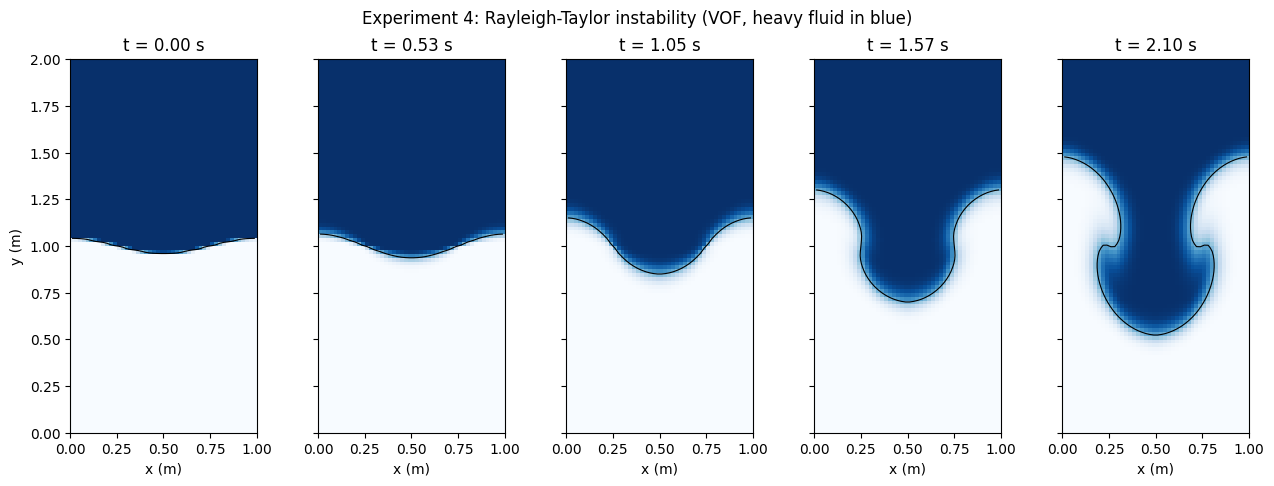

In [10]:
fig, axs = plt.subplots(1, len(snapshots), figsize=(13, 4.8), sharex=True, sharey=True)
for ax, (ti, ai) in zip(axs, snapshots):
    ax.imshow(ai, origin="lower", extent=(0, Lx, 0, Ly), cmap="Blues", vmin=0, vmax=1)
    ax.contour(x, y, ai, levels=[0.5], colors="k", linewidths=0.8)
    ax.set_title(f"t = {ti:.2f} s")
    ax.set_xlabel("x (m)")
axs[0].set_ylabel("y (m)")
fig.suptitle("Experiment 4: Rayleigh-Taylor instability (VOF, heavy fluid in blue)")
fig.tight_layout()
fig.savefig("experiment_4_rti_output.png", dpi=180)
plt.show()

### Numerical summary at the snapshot times

In [11]:
print(f"{'t (s)':>8}{'h_spike (m)':>13}{'h_bubble (m)':>14}{'amp a (m)':>11}{'max|u| (m/s)':>14}{'E_k (J/m)':>12}{'smear area':>12}")
for d in res["snap_diag"]:
    print(f"{d['t']:>8.4f}{d['h_spike']:>13.4f}{d['h_bubble']:>14.4f}{d['amp']:>11.4f}{d['max_speed']:>14.5f}{d['ke']:>12.5f}{d['smear']:>12.5f}")

   t (s)  h_spike (m)  h_bubble (m)  amp a (m)  max|u| (m/s)   E_k (J/m)  smear area
  0.0000       0.0407        0.0407     0.0407       0.00000     0.00000     0.02083
  0.5250       0.0634        0.0634     0.0634       0.10504     0.00116     0.05903
  1.0500       0.1502        0.1502     0.1502       0.26441     0.00938     0.12674
  1.5750       0.3001        0.3001     0.3001       0.48319     0.04630     0.23611
  2.1000       0.4769        0.4769     0.4769       0.82186     0.14321     0.41667


### Time histories of the diagnostics
Panels: (a) spike and bubble penetration, (b) maximum velocity, (c) kinetic energy (log scale), (d) heavy-fluid area error and maximum divergence after projection (log scale).

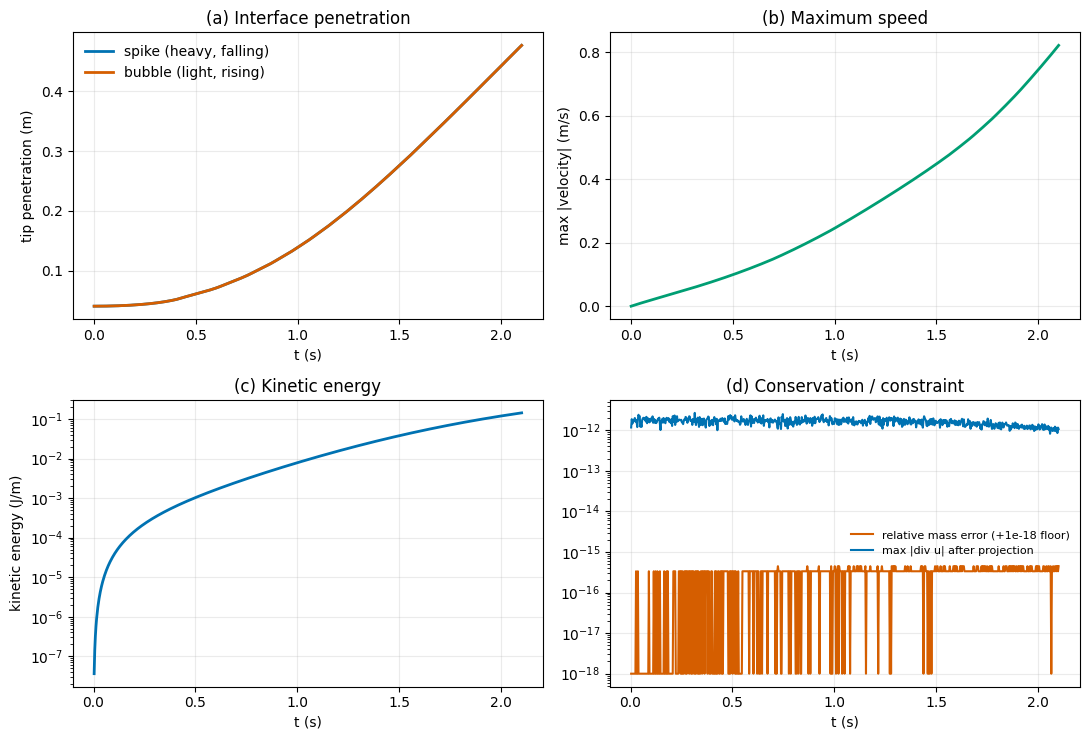

Peak max speed = 0.82186 m/s at t = 2.100 s
Final E_k      = 0.14321 J/m
Largest relative mass deviation over run = 4.441e-16
Largest post-projection |div u| over run = 2.675e-12


In [12]:
t_h = hist["t"]
C1, C2, C3 = "#0072B2", "#D55E00", "#009E73"
fig, axs = plt.subplots(2, 2, figsize=(11, 7.5))
ax = axs[0, 0]
ax.plot(t_h, hist["h_spike"], color=C1, lw=2, label="spike (heavy, falling)")
ax.plot(t_h, hist["h_bubble"], color=C2, lw=2, label="bubble (light, rising)")
ax.set_xlabel("t (s)"); ax.set_ylabel("tip penetration (m)"); ax.set_title("(a) Interface penetration"); ax.legend(frameon=False)
ax = axs[0, 1]
ax.plot(t_h, hist["max_speed"], color=C3, lw=2)
ax.set_xlabel("t (s)"); ax.set_ylabel("max |velocity| (m/s)"); ax.set_title("(b) Maximum speed")
ax = axs[1, 0]
ax.semilogy(t_h[1:], hist["ke"][1:], color=C1, lw=2)
ax.set_xlabel("t (s)"); ax.set_ylabel("kinetic energy (J/m)"); ax.set_title("(c) Kinetic energy")
ax = axs[1, 1]
ax.semilogy(t_h[1:], np.abs(hist["mass"][1:] - hist["mass"][0]) / hist["mass"][0] + 1e-18, color=C2, lw=1.5, label="relative mass error (+1e-18 floor)")
ax.semilogy(t_h[1:], hist["div"][1:], color=C1, lw=1.5, label="max |div u| after projection")
ax.set_xlabel("t (s)"); ax.set_title("(d) Conservation / constraint"); ax.legend(frameon=False, fontsize=8)
for a in axs.ravel():
    a.grid(alpha=0.25)
fig.tight_layout()
fig.savefig("fig_diagnostics.png", dpi=180)
plt.show()
print(f"Peak max speed = {hist['max_speed'].max():.5f} m/s at t = {t_h[np.argmax(hist['max_speed'])]:.3f} s")
print(f"Final E_k      = {hist['ke'][-1]:.5f} J/m")
print(f"Largest relative mass deviation over run = {np.max(np.abs(hist['mass']-hist['mass'][0]))/hist['mass'][0]:.3e}")
print(f"Largest post-projection |div u| over run = {hist['div'].max():.3e}")

### Early-time growth rate versus linear theory
For motion starting from rest, linear theory predicts $a(t)=a_0\cosh(\sigma t)$. The growth rate $\sigma$ is fitted by least squares to the measured amplitude $a(t)=\tfrac12(h_s+h_b)$ over the window in which the amplitude is still small, defined as $a<a_{max}$. The window is varied ($a_{max}=0.08,\,0.10,\,0.12$ m, i.e. $0.08\lambda$–$0.12\lambda$) to show how sensitive the estimate is. The measured values are compared with the inviscid and approximate viscous theoretical rates computed in Section 2.

In [13]:
a0_meas = hist["amp"][0]

def fit_sigma(t, a, a_max, a0=None):
    a0 = a[0] if a0 is None else a0
    m = a <= a_max
    tt, aa = t[m], a[m]
    cost = lambda s: np.sum((aa - a0 * np.cosh(s * tt)) ** 2)
    out = minimize_scalar(cost, bounds=(0.1, 6.0), method="bounded")
    return out.x, tt[-1], m.sum()

print(f"measured initial amplitude a0 = {a0_meas:.4f} m (nominal {amp0})")
print(f"theory: sigma_inviscid = {sigma_inviscid:.4f} 1/s, sigma_viscous(approx) = {sigma_viscous:.4f} 1/s\n")
fit_rows = []
print(f"{'a_max (m)':>10}{'t_window (s)':>14}{'n_points':>10}{'sigma_fit (1/s)':>17}{'/sigma_inv':>12}{'/sigma_visc':>13}")
for a_max in (0.08, 0.10, 0.12):
    s, t_win, n = fit_sigma(t_h, hist["amp"], a_max)
    fit_rows.append(dict(a_max=a_max, t_window=float(t_win), n=int(n), sigma=float(s)))
    print(f"{a_max:>10.2f}{t_win:>14.3f}{n:>10d}{s:>17.4f}{s/sigma_inviscid:>12.3f}{s/sigma_viscous:>13.3f}")
sigma_fit = fit_rows[1]["sigma"]     # a_max = 0.10 (0.1 lambda) is the reference window

measured initial amplitude a0 = 0.0407 m (nominal 0.04)
theory: sigma_inviscid = 2.3672 1/s, sigma_viscous(approx) = 2.1780 1/s

 a_max (m)  t_window (s)  n_points  sigma_fit (1/s)  /sigma_inv  /sigma_visc
      0.08         0.663       222           1.9177       0.810        0.881
      0.10         0.798       267           1.9331       0.817        0.888
      0.12         0.906       303           1.9298       0.815        0.886


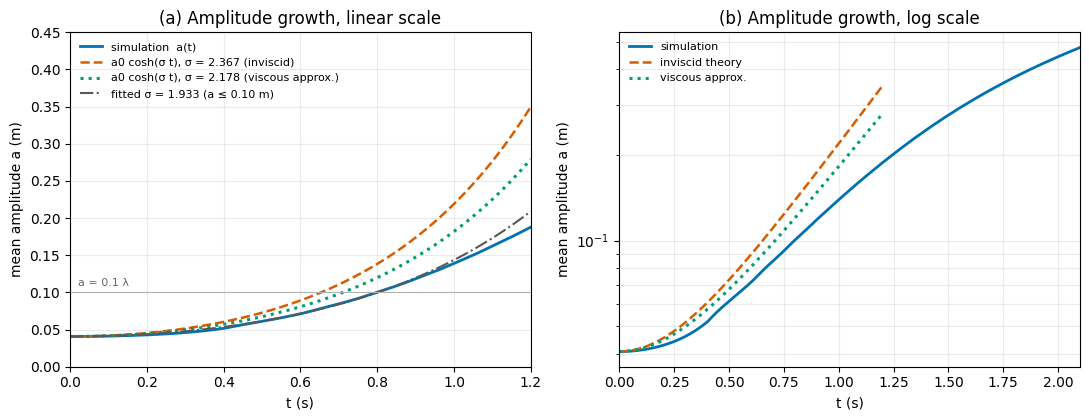

In [14]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
tt = np.linspace(0, 1.2, 300)
ax = axs[0]
ax.plot(t_h, hist["amp"], color=C1, lw=2, label="simulation  a(t)")
ax.plot(tt, a0_meas * np.cosh(sigma_inviscid * tt), "--", color=C2, lw=1.8, label=f"a0 cosh(σ t), σ = {sigma_inviscid:.3f} (inviscid)")
ax.plot(tt, a0_meas * np.cosh(sigma_viscous * tt), ":", color=C3, lw=2.2, label=f"a0 cosh(σ t), σ = {sigma_viscous:.3f} (viscous approx.)")
ax.plot(tt, a0_meas * np.cosh(sigma_fit * tt), "-.", color="0.35", lw=1.5, label=f"fitted σ = {sigma_fit:.3f} (a ≤ 0.10 m)")
ax.axhline(0.1 * Lx, color="0.7", lw=0.8)
ax.text(0.02, 0.1 * Lx + 0.008, "a = 0.1 λ", color="0.4", fontsize=8)
ax.set_xlim(0, 1.2); ax.set_ylim(0, 0.45)
ax.set_xlabel("t (s)"); ax.set_ylabel("mean amplitude a (m)"); ax.set_title("(a) Amplitude growth, linear scale")
ax.legend(frameon=False, fontsize=8, loc="upper left"); ax.grid(alpha=0.25)
ax = axs[1]
ax.semilogy(t_h, hist["amp"], color=C1, lw=2, label="simulation")
ax.semilogy(tt, a0_meas * np.cosh(sigma_inviscid * tt), "--", color=C2, lw=1.8, label="inviscid theory")
ax.semilogy(tt, a0_meas * np.cosh(sigma_viscous * tt), ":", color=C3, lw=2.2, label="viscous approx.")
ax.set_xlim(0, t_end); ax.set_xlabel("t (s)"); ax.set_ylabel("mean amplitude a (m)"); ax.set_title("(b) Amplitude growth, log scale")
ax.legend(frameon=False, fontsize=8); ax.grid(alpha=0.25, which="both")
fig.tight_layout()
fig.savefig("fig_growth.png", dpi=180)
plt.show()

### Final flow field
Cell-centred velocity (interpolated from the staggered faces) at $t=t_{end}$, with the $\alpha=0.5$ interface. Colour shows speed.

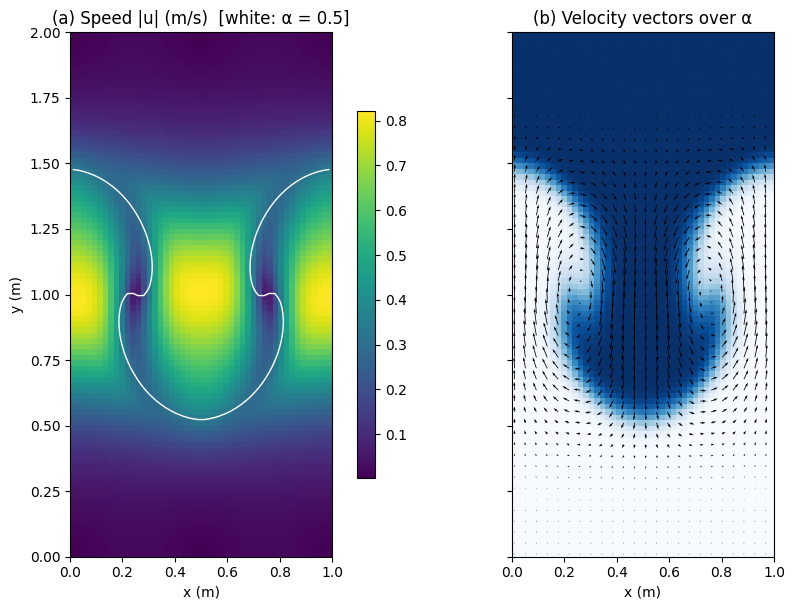

Maximum cell-centred speed = 0.82171 m/s at (x, y) = (0.490, 1.010) m
Left-right symmetry error of alpha, max|alpha(x) - alpha(Lx-x)| = 6.328e-15
Interface smearing area (0.05<alpha<0.95): initial 0.0208 m^2 -> final 0.4167 m^2


In [15]:
uc = 0.5 * (u + np.roll(u, -1, axis=1))
vc = 0.5 * (v[1:] + v[:-1])
speed = np.hypot(uc, vc)
fig, axs = plt.subplots(1, 2, figsize=(10, 6.2), sharey=True)
ax = axs[0]
im = ax.imshow(speed, origin="lower", extent=(0, Lx, 0, Ly), cmap="viridis")
ax.contour(x, y, alpha, levels=[0.5], colors="w", linewidths=1.0)
ax.set_title("(a) Speed |u| (m/s)  [white: α = 0.5]"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)")
fig.colorbar(im, ax=ax, shrink=0.7)
ax = axs[1]
ax.imshow(alpha, origin="lower", extent=(0, Lx, 0, Ly), cmap="Blues", vmin=0, vmax=1)
s = 2
ax.quiver(x[::s], y[::s*1], uc[::s, ::s], vc[::s, ::s], color="k", scale=12, width=0.003)
ax.set_title("(b) Velocity vectors over α"); ax.set_xlabel("x (m)")
fig.tight_layout()
fig.savefig("fig_flow_field.png", dpi=180)
plt.show()
iy, ix = np.unravel_index(np.argmax(speed), speed.shape)
print(f"Maximum cell-centred speed = {speed.max():.5f} m/s at (x, y) = ({x[ix]:.3f}, {y[iy]:.3f}) m")
sym = np.max(np.abs(alpha - alpha[:, ::-1]))
print(f"Left-right symmetry error of alpha, max|alpha(x) - alpha(Lx-x)| = {sym:.3e}")
print(f"Interface smearing area (0.05<alpha<0.95): initial {hist['smear'][0]:.4f} m^2 -> final {hist['smear'][-1]:.4f} m^2")

## Grid-sensitivity study

The same parameters are run on a coarser (24×48) and a finer (96×192) grid (the 48×96 result is reused). The time step follows the same adaptive formula, so it differs between grids when the viscous or CFL limits are tighter than 0.003 s. The comparison shows how much the first-order upwind VOF result depends on resolution.

In [16]:
runs = {"24x48": run_rti(24, 48, Lx, Ly, t_end, nu, g, rho_light, rho_heavy, amp0),
        "48x96": res,
        "96x192": run_rti(96, 192, Lx, Ly, t_end, nu, g, rho_light, rho_heavy, amp0)}
grid_rows = []
print(f"{'grid':>8}{'steps':>7}{'h_spike':>9}{'h_bubble':>10}{'max|u|':>9}{'E_k':>9}{'smear':>9}{'sigma_fit':>10}{'mass err':>11}{'max div':>11}{'wall (s)':>9}")
for name, r in runs.items():
    h = r["hist"]
    s_fit, _, _ = fit_sigma(h["t"], h["amp"], 0.10)
    row = dict(grid=name, steps=r["steps"], h_spike=float(h["h_spike"][-1]), h_bubble=float(h["h_bubble"][-1]),
               max_speed=float(h["max_speed"][-1]), ke=float(h["ke"][-1]), smear=float(h["smear"][-1]),
               sigma_fit=float(s_fit),
               mass_err=float(abs(r["mass"] - r["initial_mass"]) / r["initial_mass"]),
               max_div=float(r["maximum_divergence"]), wall=float(r["wall"]))
    grid_rows.append(row)
    print(f"{name:>8}{row['steps']:>7d}{row['h_spike']:>9.4f}{row['h_bubble']:>10.4f}{row['max_speed']:>9.4f}{row['ke']:>9.4f}{row['smear']:>9.4f}{row['sigma_fit']:>10.4f}{row['mass_err']:>11.2e}{row['max_div']:>11.2e}{row['wall']:>9.1f}")
print(f"\ntheory: sigma_inviscid = {sigma_inviscid:.4f}, sigma_viscous(approx) = {sigma_viscous:.4f}")

    grid  steps  h_spike  h_bubble   max|u|      E_k    smear sigma_fit   mass err    max div wall (s)
   24x48    700   0.4664    0.4664   0.7432   0.1188   0.5278    1.8333   3.33e-16   1.23e-13      0.3
   48x96    700   0.4769    0.4769   0.8219   0.1432   0.4167    1.9331   4.44e-16   2.68e-12      0.7
  96x192    861   0.4809    0.4809   0.8750   0.1586   0.3082    1.9859   1.67e-15   2.70e-11      3.0

theory: sigma_inviscid = 2.3672, sigma_viscous(approx) = 2.1780


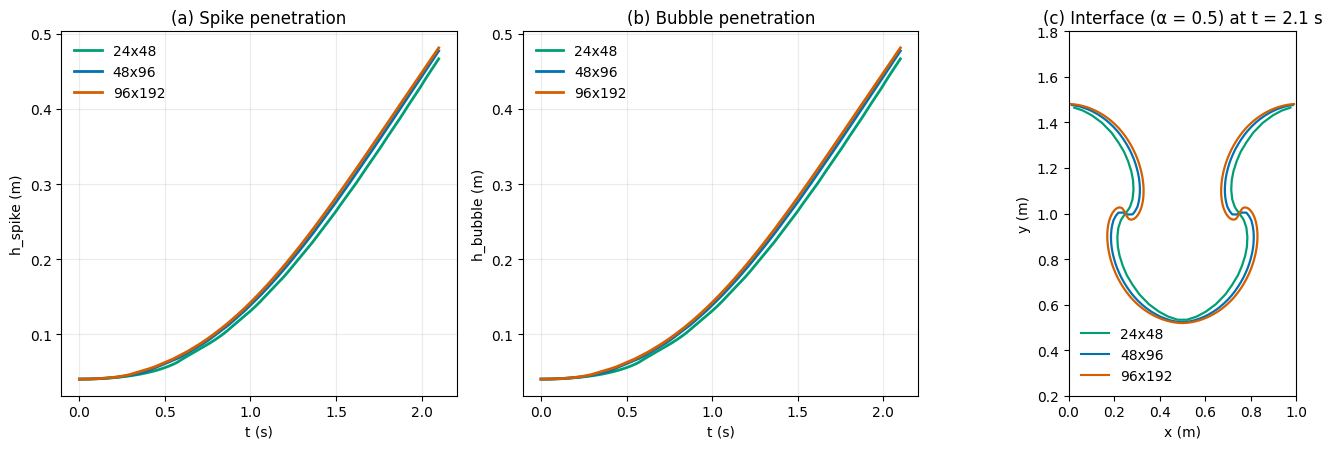

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.6))
cols = {"24x48": "#009E73", "48x96": "#0072B2", "96x192": "#D55E00"}
ax = axs[0]
for name, r in runs.items():
    ax.plot(r["hist"]["t"], r["hist"]["h_spike"], color=cols[name], lw=2, label=name)
ax.set_title("(a) Spike penetration"); ax.set_xlabel("t (s)"); ax.set_ylabel("h_spike (m)"); ax.legend(frameon=False); ax.grid(alpha=0.25)
ax = axs[1]
for name, r in runs.items():
    ax.plot(r["hist"]["t"], r["hist"]["h_bubble"], color=cols[name], lw=2, label=name)
ax.set_title("(b) Bubble penetration"); ax.set_xlabel("t (s)"); ax.set_ylabel("h_bubble (m)"); ax.legend(frameon=False); ax.grid(alpha=0.25)
ax = axs[2]
for name, r in runs.items():
    ax.contour(r["x"], r["y"], r["alpha"], levels=[0.5], colors=[cols[name]], linewidths=1.6)
ax.plot([], [], color=cols["24x48"], label="24x48"); ax.plot([], [], color=cols["48x96"], label="48x96"); ax.plot([], [], color=cols["96x192"], label="96x192")
ax.set_xlim(0, Lx); ax.set_ylim(0.2, 1.8); ax.set_aspect("equal")
ax.set_title(f"(c) Interface (α = 0.5) at t = {t_end} s"); ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.legend(frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("fig_grid_study.png", dpi=180)
plt.show()